# Retail Sales Forecasting System

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Statistical analysis
from scipy import stats

# Date handling
from datetime import timedelta

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

# Dataset Information

In [2]:
df = pd.read_csv(r"C:\Users\amans\Downloads\retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 9


In [6]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [7]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


# Missing Values

In [8]:
missing_values = df.isnull().sum()

missing_df = pd.DataFrame({
    "Column": missing_values.index,
    "Missing Values": missing_values.values,
    "Missing Percentage": 
        (missing_values.values / len(df)) * 100
})

missing_df.sort_values(
    by="Missing Values",
    ascending=False
)

,Column,Missing Values,Missing Percentage
0,Transaction ID,0,0.0
1,Date,0,0.0
2,Customer ID,0,0.0
3,Gender,0,0.0
4,Age,0,0.0
5,Product Category,0,0.0
6,Quantity,0,0.0
7,Price per Unit,0,0.0
8,Total Amount,0,0.0


# Duplicate Data

In [9]:
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("New shape:", df.shape)

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
New shape: (1000, 9)


# Column List

In [10]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print(df.columns.tolist())

['transaction_id', 'date', 'customer_id', 'gender', 'age', 'product_category', 'quantity', 'price_per_unit', 'total_amount']


In [11]:
possible_date_columns = [
    "date",
    "order_date",
    "sales_date",
    "transaction_date",
    "purchase_date"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    print("No standard date column found.")
    print("Available columns:", df.columns.tolist())
else:
    print("Date column detected:", date_column)

Date column detected: date


In [12]:
if date_column is not None:
    df[date_column] = pd.to_datetime(
        df[date_column],
        errors="coerce"
    )

    print(df[date_column].dtype)
    print(df[date_column].head())

datetime64[ns]
0   2023-11-24
1   2023-02-27
2   2023-01-13
3   2023-05-21
4   2023-05-06
Name: date, dtype: datetime64[ns]


In [13]:
if date_column is not None:
    print(
        "Invalid dates:",
        df[date_column].isna().sum()
    )

Invalid dates: 0


# Dataset Shape

In [15]:
if date_column is not None:
    df = df.dropna(subset=[date_column])

print("Dataset shape:", df.shape)

Dataset shape: (1000, 9)


In [16]:
possible_sales_columns = [
    "total_amount",
    "sales",
    "revenue",
    "sales_amount",
    "amount",
    "total_sales",
    "purchase_amount"
]

sales_column = None

for col in possible_sales_columns:
    if col in df.columns:
        sales_column = col
        break

if sales_column is None:
    print("Sales column not automatically detected.")
    print(df.columns.tolist())
else:
    print("Sales column detected:", sales_column)

Sales column detected: total_amount


In [17]:
if sales_column is not None:

    df[sales_column] = pd.to_numeric(
        df[sales_column],
        errors="coerce"
    )

    print(df[sales_column].dtype)

int64


In [18]:
df = df.dropna(subset=[sales_column])

print("Rows after removing invalid sales:", len(df))

Rows after removing invalid sales: 1000


In [20]:
df.describe(include="all")

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
count,1000.000000,1000,1000,1000,1000.00000,1000,1000.000000,1000.000000,1000.000000
unique,NaN,NaN,1000,2,NaN,3,NaN,NaN,NaN
top,NaN,NaN,CUST001,Female,NaN,Clothing,NaN,NaN,NaN
freq,NaN,NaN,1,510,NaN,351,NaN,NaN,NaN
mean,500.500000,2023-07-03 00:25:55.200000256,NaN,NaN,41.39200,NaN,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,NaN,NaN,18.00000,NaN,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,NaN,NaN,29.00000,NaN,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,NaN,NaN,42.00000,NaN,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,NaN,NaN,53.00000,NaN,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,NaN,NaN,64.00000,NaN,4.000000,500.000000,2000.000000


In [21]:
negative_sales = df[df[sales_column] < 0]

print("Negative sales records:", len(negative_sales))

Negative sales records: 0


In [22]:
df = df[df[sales_column] >= 0]

print("Shape after removing negative sales:", df.shape)

Shape after removing negative sales: (1000, 9)


# Outlier Detection

In [23]:
Q1 = df[sales_column].quantile(0.25)
Q3 = df[sales_column].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 60.0
Q3: 900.0
IQR: 840.0
Lower Bound: -1200.0
Upper Bound: 2160.0


In [24]:
outliers = df[
    (df[sales_column] < lower_bound) |
    (df[sales_column] > upper_bound)
]

print("Number of outliers:", len(outliers))
print("Outlier percentage:", len(outliers) / len(df) * 100)

Number of outliers: 0
Outlier percentage: 0.0


# Sales Distribution and Outliers

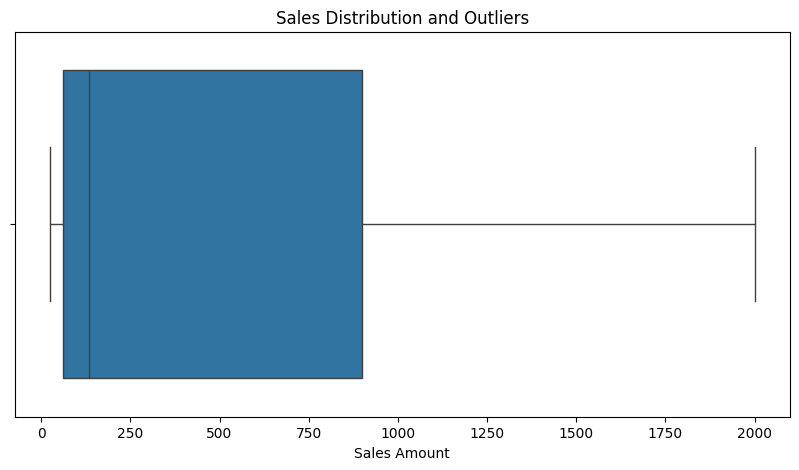

In [25]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df[sales_column]
)

plt.title("Sales Distribution and Outliers")
plt.xlabel("Sales Amount")

plt.show()

In [26]:
df[sales_column] = np.clip(
    df[sales_column],
    lower_bound,
    upper_bound
)

print("Outliers capped successfully.")

Outliers capped successfully.


In [27]:
if date_column is not None:

    df["year"] = df[date_column].dt.year
    df["month"] = df[date_column].dt.month
    df["day"] = df[date_column].dt.day
    df["day_of_week"] = df[date_column].dt.dayofweek
    df["quarter"] = df[date_column].dt.quarter
    df["week_of_year"] = df[date_column].dt.isocalendar().week.astype(int)
    df["is_weekend"] = (
        df[date_column].dt.dayofweek >= 5
    ).astype(int)

df.head()

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount,year,month,day,day_of_week,quarter,week_of_year,is_weekend
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023,11,24,4,4,47,0
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023,2,27,0,1,9,0
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023,1,13,4,1,2,0
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023,5,21,6,2,20,1
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023,5,6,5,2,18,1


# Sales Distribution

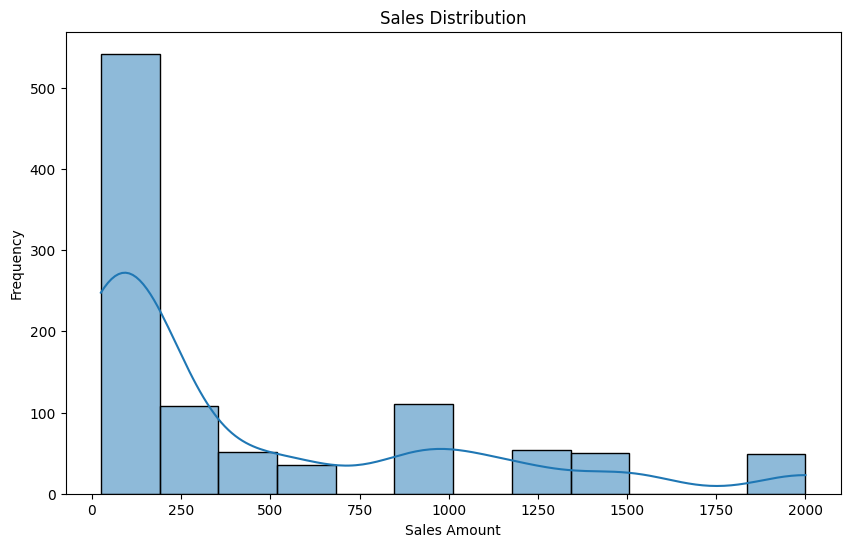

In [28]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df[sales_column],
    kde=True
)

plt.title("Sales Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")

plt.show()

# Yearly Sales Dataset

In [29]:
yearly_sales = (
    df.groupby("year")[sales_column]
    .sum()
    .reset_index()
)

yearly_sales

,year,total_amount
0,2023,454470
1,2024,1530


# Yearly Sales Trend

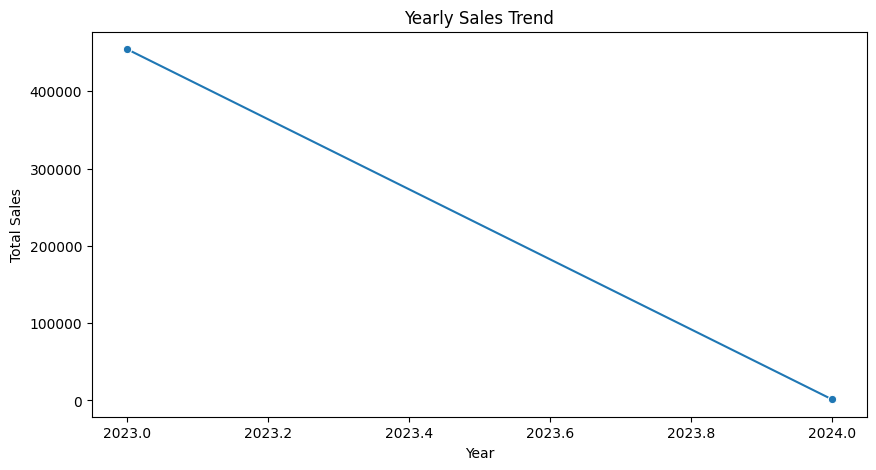

In [30]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_sales,
    x="year",
    y=sales_column,
    marker="o"
)

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.show()

# Monthly Sales

In [32]:
monthly_sales = (
    df.groupby(
        ["year", "month"]
    )[sales_column]
    .sum()
    .reset_index()
)

monthly_sales["year_month"] = (
    monthly_sales["year"].astype(str)
    + "-"
    + monthly_sales["month"].astype(str).str.zfill(2)
)

monthly_sales.head()

,year,month,total_amount,year_month
0,2023,1,35450,2023-01
1,2023,2,44060,2023-02
2,2023,3,28990,2023-03
3,2023,4,33870,2023-04
4,2023,5,53150,2023-05


# Monthly Sales Trend

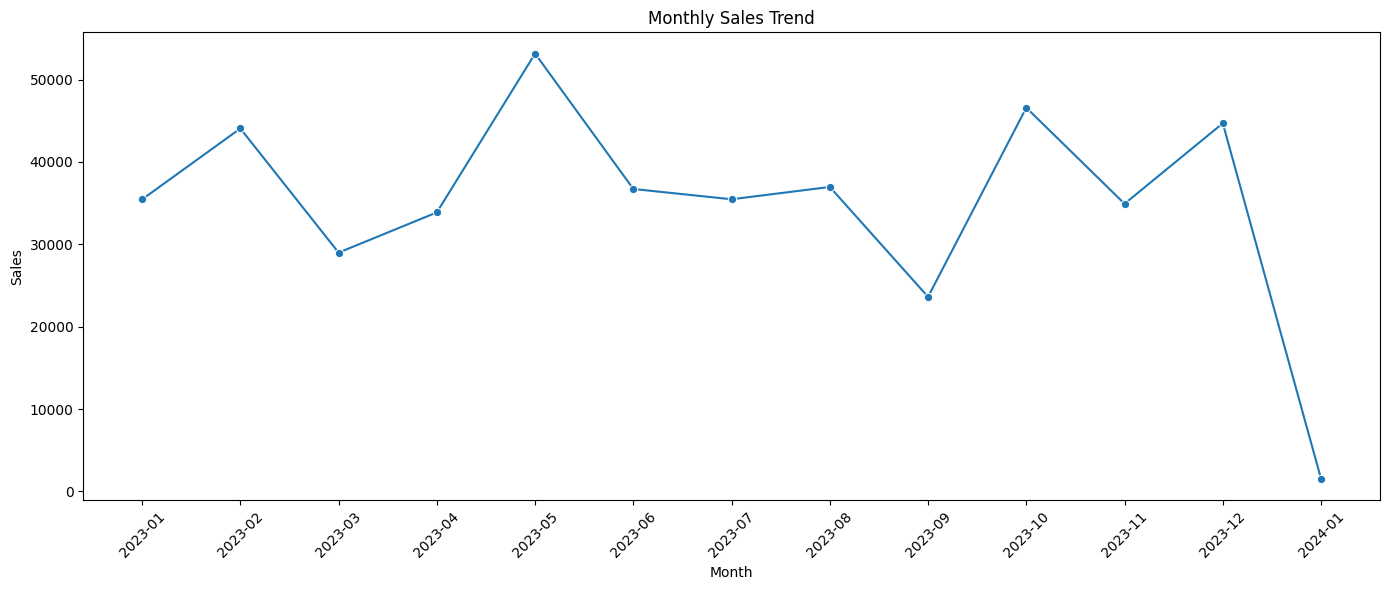

In [33]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="year_month",
    y=sales_column,
    marker="o"
)

plt.xticks(rotation=45)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()

# Weekday Sales

In [34]:
weekday_sales = (
    df.groupby("day_of_week")[sales_column]
    .sum()
    .reset_index()
)

weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_sales["day_name"] = (
    weekday_sales["day_of_week"]
    .map(weekday_names)
)

weekday_sales

,day_of_week,total_amount,day_name
0,0,70250,Monday
1,1,69440,Tuesday
2,2,58770,Wednesday
3,3,53835,Thursday
4,4,66290,Friday
5,5,78815,Saturday
6,6,58600,Sunday


# Sales by Day of Week

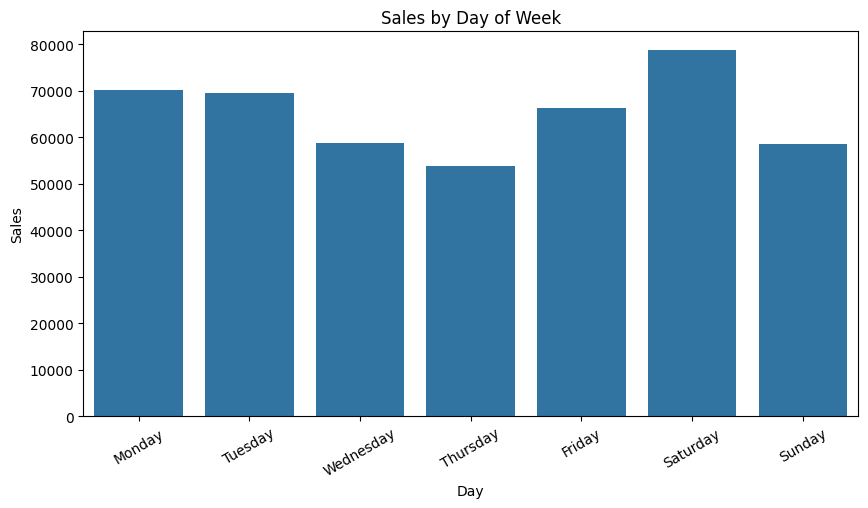

In [35]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_sales,
    x="day_name",
    y=sales_column
)

plt.title("Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Sales")

plt.xticks(rotation=30)

plt.show()

In [36]:
possible_category_columns = [
    "product_category",
    "category",
    "product",
    "product_name"
]

category_column = None

for col in possible_category_columns:
    if col in df.columns:
        category_column = col
        break

print("Category column:", category_column)

Category column: product_category


# Category Sales

In [37]:
if category_column is not None:

    category_sales = (
        df.groupby(category_column)[sales_column]
        .sum()
        .sort_values(ascending=False)
    )

    print(category_sales)

product_category
Electronics    156905
Clothing       155580
Beauty         143515
Name: total_amount, dtype: int64


# Sales by Category

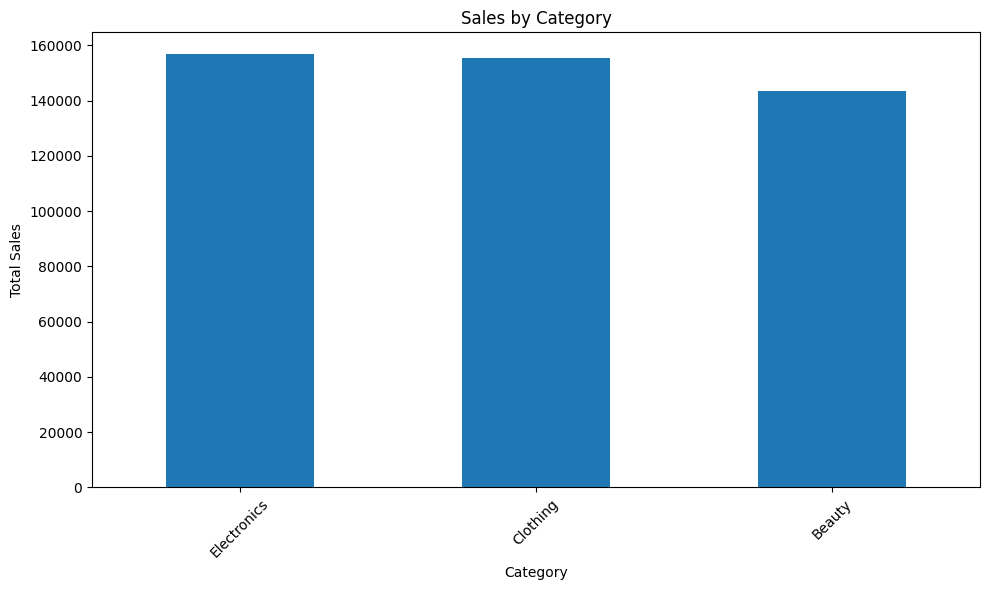

In [38]:
if category_column is not None:

    plt.figure(figsize=(10, 6))

    category_sales.plot(
        kind="bar"
    )

    plt.title("Sales by Category")
    plt.xlabel("Category")
    plt.ylabel("Total Sales")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

# Correlation Matrix

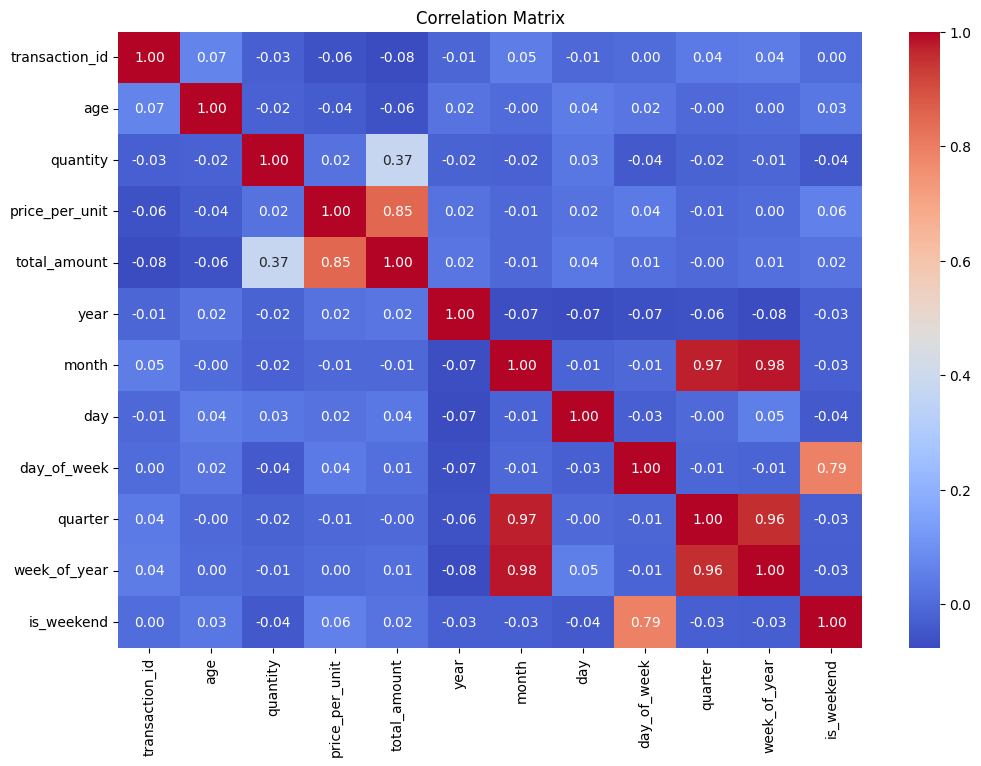

In [39]:
numeric_df = df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

# Daily Sales Dataset

In [40]:
daily_sales = (
    df.groupby(date_column)[sales_column]
    .sum()
    .reset_index()
)

daily_sales = daily_sales.sort_values(
    by=date_column
)

daily_sales.head()

,date,total_amount
0,2023-01-01,3600
1,2023-01-02,1765
2,2023-01-03,600
3,2023-01-04,1240
4,2023-01-05,1100


In [41]:
date_range = pd.date_range(
    start=daily_sales[date_column].min(),
    end=daily_sales[date_column].max(),
    freq="D"
)

daily_sales = (
    daily_sales
    .set_index(date_column)
    .reindex(date_range)
)

daily_sales.index.name = date_column

daily_sales[sales_column] = (
    daily_sales[sales_column]
    .fillna(0)
)

daily_sales = daily_sales.reset_index()

daily_sales.head()

,date,total_amount
0,2023-01-01,3600.0
1,2023-01-02,1765.0
2,2023-01-03,600.0
3,2023-01-04,1240.0
4,2023-01-05,1100.0


# Daily Sales Trend

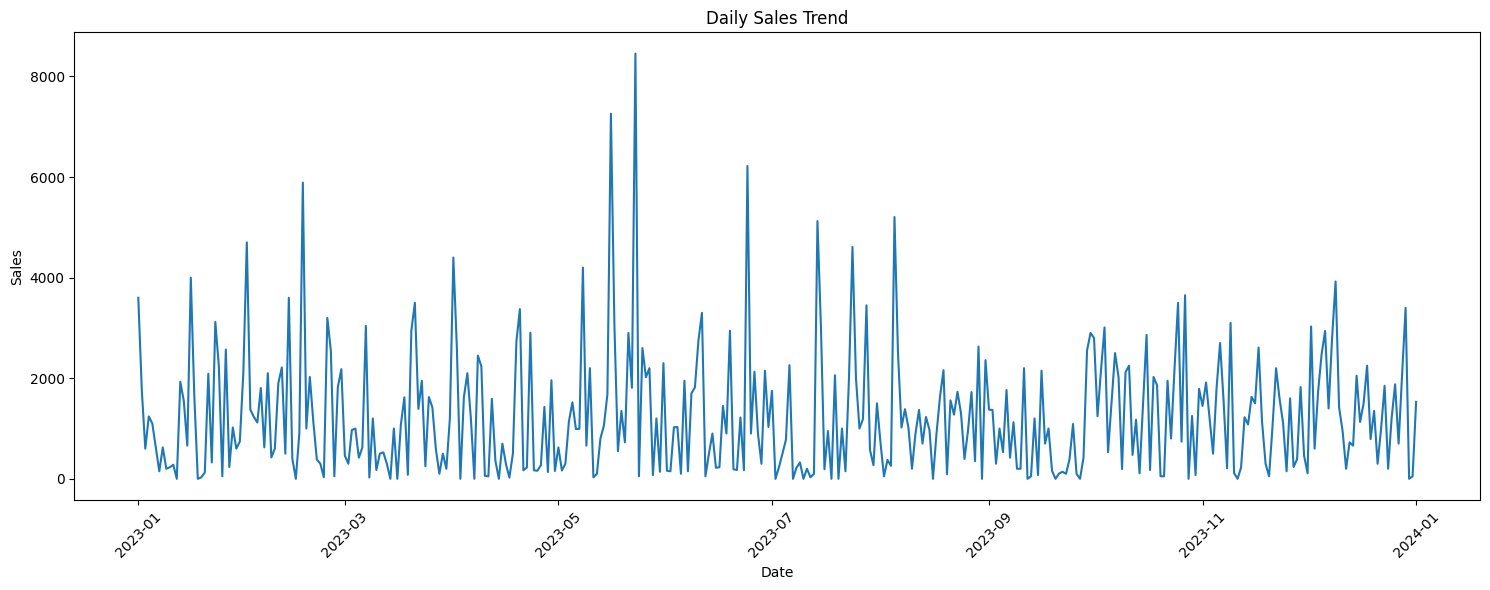

In [42]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales[date_column],
    daily_sales[sales_column]
)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Sales Trend with Moving Averages

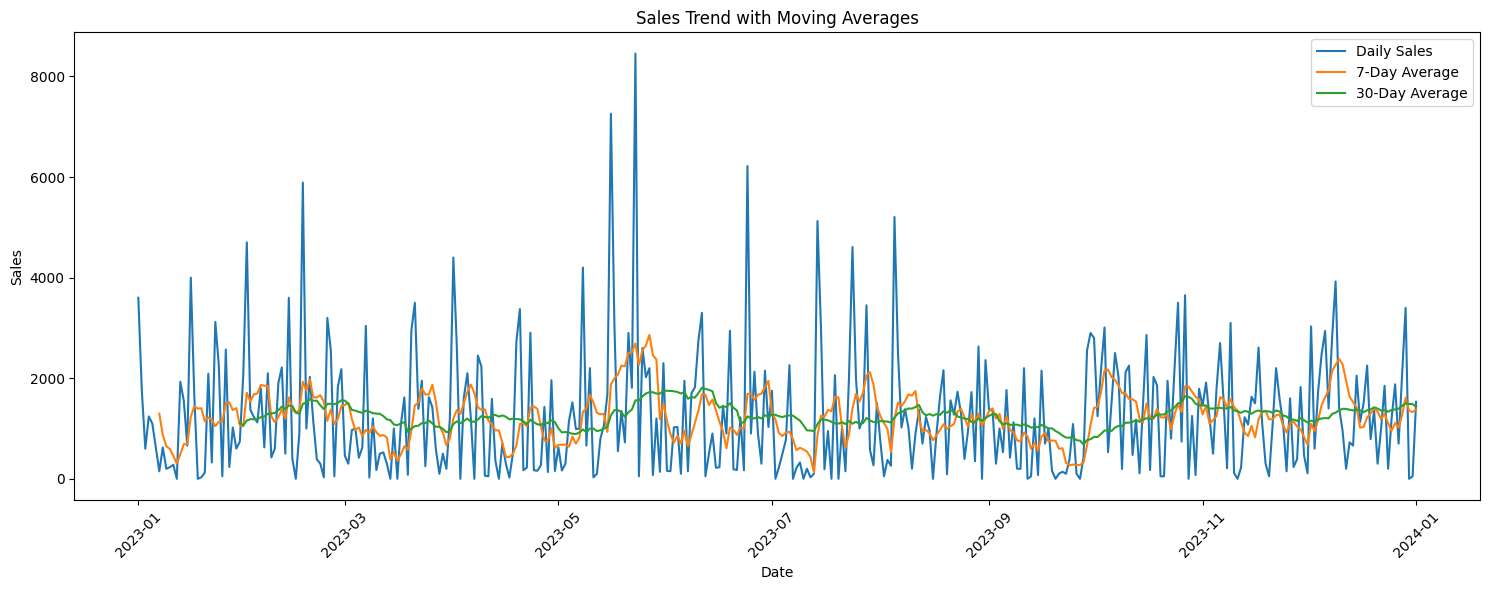

In [44]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales[date_column],
    daily_sales[sales_column],
    label="Daily Sales"
)

plt.plot(
    daily_sales[date_column],
    daily_sales["rolling_7"],
    label="7-Day Average"
)

plt.plot(
    daily_sales[date_column],
    daily_sales["rolling_30"],
    label="30-Day Average"
)

plt.title("Sales Trend with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [45]:
model_df = daily_sales.copy()

model_df["lag_1"] = model_df[sales_column].shift(1)
model_df["lag_7"] = model_df[sales_column].shift(7)
model_df["lag_14"] = model_df[sales_column].shift(14)
model_df["lag_30"] = model_df[sales_column].shift(30)

model_df["rolling_mean_7"] = (
    model_df[sales_column]
    .shift(1)
    .rolling(7)
    .mean()
)

model_df["rolling_mean_14"] = (
    model_df[sales_column]
    .shift(1)
    .rolling(14)
    .mean()
)

model_df["rolling_mean_30"] = (
    model_df[sales_column]
    .shift(1)
    .rolling(30)
    .mean()
)

model_df.head()

,date,total_amount,rolling_7,rolling_30,lag_1,lag_7,lag_14,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30
0,2023-01-01,3600.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-02,1765.0,NaN,NaN,3600.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2023-01-03,600.0,NaN,NaN,1765.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2023-01-04,1240.0,NaN,NaN,600.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2023-01-05,1100.0,NaN,NaN,1240.0,NaN,NaN,NaN,NaN,NaN,NaN


In [46]:
model_df["year"] = (
    model_df[date_column].dt.year
)

model_df["month"] = (
    model_df[date_column].dt.month
)

model_df["day"] = (
    model_df[date_column].dt.day
)

model_df["day_of_week"] = (
    model_df[date_column].dt.dayofweek
)

model_df["quarter"] = (
    model_df[date_column].dt.quarter
)

model_df["day_of_year"] = (
    model_df[date_column].dt.dayofyear
)

model_df["week_of_year"] = (
    model_df[date_column]
    .dt.isocalendar()
    .week
    .astype(int)
)

In [47]:
model_df = model_df.dropna()

print("Model dataset shape:", model_df.shape)

model_df.head()

Model dataset shape: (336, 18)


,date,total_amount,rolling_7,rolling_30,lag_1,lag_7,lag_14,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30,year,month,day,day_of_week,quarter,day_of_year,week_of_year
30,2023-01-31,2100.0,1045.000000,1061.666667,740.0,2250.0,1645.0,3600.0,1066.428571,1057.142857,1111.666667,2023,1,31,1,1,31,5
31,2023-02-01,4700.0,1709.285714,1159.500000,2100.0,50.0,0.0,1765.0,1045.000000,1089.642857,1061.666667,2023,2,1,2,1,32,5
32,2023-02-02,1375.0,1538.571429,1185.333333,4700.0,2570.0,30.0,600.0,1709.285714,1425.357143,1159.500000,2023,2,2,3,1,33,5
33,2023-02-03,1230.0,1680.714286,1185.000000,1375.0,235.0,125.0,1240.0,1538.571429,1521.428571,1185.333333,2023,2,3,4,1,34,5
34,2023-02-04,1120.0,1695.000000,1185.666667,1230.0,1020.0,2090.0,1100.0,1680.714286,1600.357143,1185.000000,2023,2,4,5,1,35,5


In [48]:
features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30",
    "year",
    "month",
    "day",
    "day_of_week",
    "quarter",
    "day_of_year",
    "week_of_year"
]

X = model_df[features]

y = model_df[sales_column]

print("Features:", features)
print("Target:", sales_column)

Features: ['lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_mean_7', 'rolling_mean_14', 'rolling_mean_30', 'year', 'month', 'day', 'day_of_week', 'quarter', 'day_of_year', 'week_of_year']
Target: total_amount


In [49]:
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 268
Testing samples: 68


In [50]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [51]:
y_pred_lr = linear_model.predict(X_test)

print(y_pred_lr[:10])

[1192.72181004  901.70357839 1001.23885607 1125.01577486 1139.75294765
 1201.34751703 1072.29262545  944.1279907  1254.73144215  866.13648491]


# Linear Regression Performance

In [52]:
mae_lr = mean_absolute_error(
    y_test,
    y_pred_lr
)

rmse_lr = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_lr
    )
)

r2_lr = r2_score(
    y_test,
    y_pred_lr
)

mape_lr = (
    np.mean(
        np.abs(
            (y_test - y_pred_lr)
            / np.where(y_test == 0, 1, y_test)
        )
    ) * 100
)

accuracy_lr = 100 - mape_lr

print("Linear Regression Performance")
print("--------------------------------")
print("MAE :", round(mae_lr, 2))
print("RMSE:", round(rmse_lr, 2))
print("R²  :", round(r2_lr, 4))
print("MAPE:", round(mape_lr, 2), "%")
print("Forecast Accuracy:", round(accuracy_lr, 2), "%")

Linear Regression Performance
--------------------------------
MAE : 794.44
RMSE: 1028.07
R²  : -0.1067
MAPE: 4225.98 %
Forecast Accuracy: -4125.98 %


In [53]:
results = pd.DataFrame({
    "Date": model_df[date_column].iloc[split_index:],
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred_lr
})

results.head()

,Date,Actual Sales,Predicted Sales
298,2023-10-26,740.0,1192.721810
299,2023-10-27,3650.0,901.703578
300,2023-10-28,0.0,1001.238856
301,2023-10-29,1250.0,1125.015775
302,2023-10-30,75.0,1139.752948


# Actual vs Predicted Sales - Linear Regression

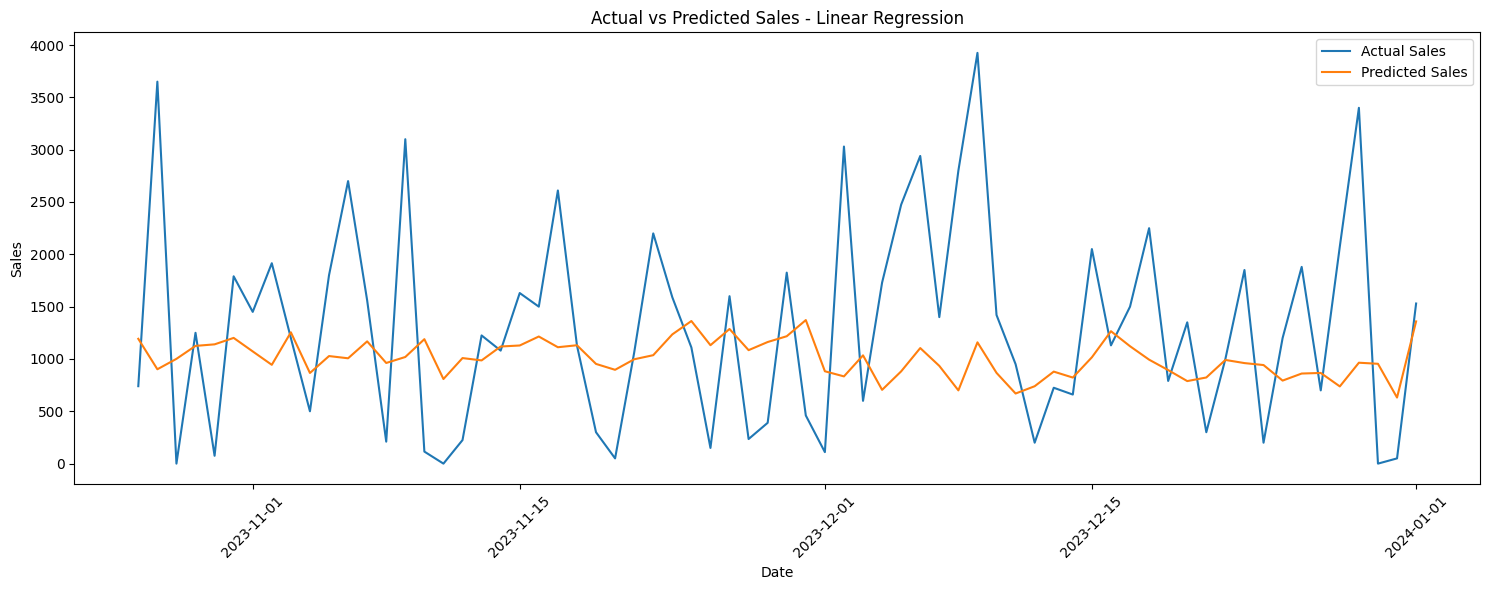

In [54]:
plt.figure(figsize=(15, 6))

plt.plot(
    results["Date"],
    results["Actual Sales"],
    label="Actual Sales"
)

plt.plot(
    results["Date"],
    results["Predicted Sales"],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales - Linear Regression")

plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [55]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=10,
    min_samples_split=5,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [56]:
y_pred_rf = rf_model.predict(X_test)

print(y_pred_rf[:10])

[1586.57191621 1901.14772687 1819.0527669  1991.93894431 2141.7358249
 1900.27699783 1763.53535396 1764.47095396 1728.67170571 1675.59958678]


# Radom Forest Performance

In [57]:
mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf
    )
)

r2_rf = r2_score(
    y_test,
    y_pred_rf
)

mape_rf = (
    np.mean(
        np.abs(
            (y_test - y_pred_rf)
            / np.where(y_test == 0, 1, y_test)
        )
    ) * 100
)

accuracy_rf = 100 - mape_rf

print("Random Forest Performance")
print("--------------------------------")
print("MAE :", round(mae_rf, 2))
print("RMSE:", round(rmse_rf, 2))
print("R²  :", round(r2_rf, 4))
print("MAPE:", round(mape_rf, 2), "%")
print("Forecast Accuracy:", round(accuracy_rf, 2), "%")

Random Forest Performance
--------------------------------
MAE : 919.62
RMSE: 1097.24
R²  : -0.2606
MAPE: 7854.95 %
Forecast Accuracy: -7754.95 %


# Feature importance

In [61]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
4,rolling_mean_7,0.157288
1,lag_7,0.142605
12,day_of_year,0.108338
3,lag_30,0.107131
6,rolling_mean_30,0.103268
2,lag_14,0.099101
0,lag_1,0.086262
9,day,0.074142
5,rolling_mean_14,0.063981
10,day_of_week,0.030152


# Random Forest Feature Importance

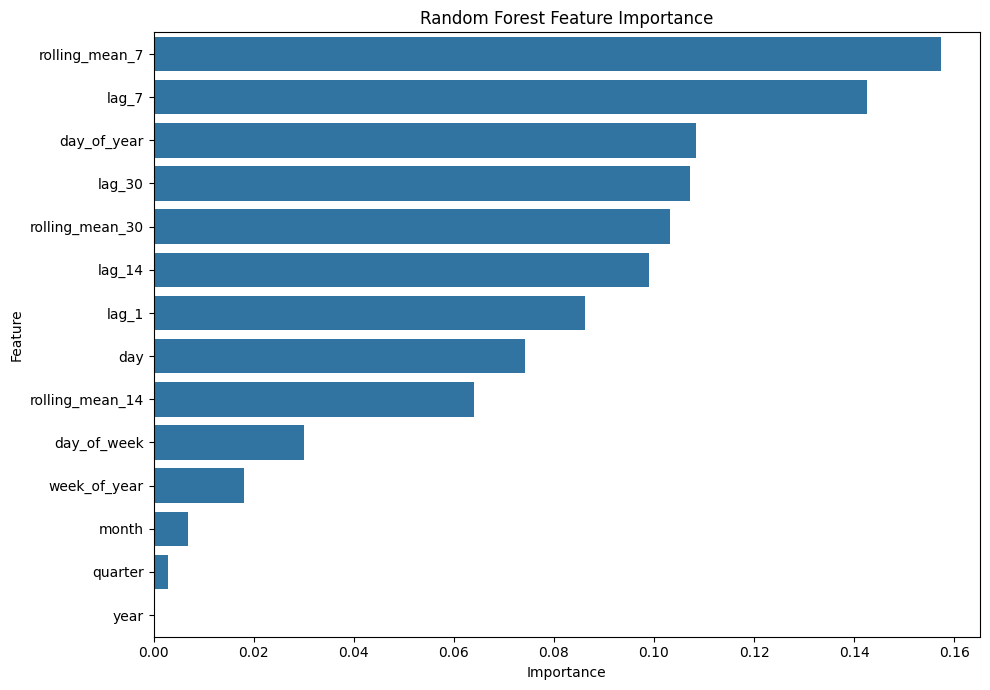

In [63]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")

plt.tight_layout()

plt.show()

In [65]:
forecast_model = rf_model

forecast_days = 30

history = list(
    model_df[sales_column].values
)

last_date = model_df[date_column].max()

future_predictions = []

for i in range(forecast_days):

    future_date = (
        last_date + timedelta(days=i + 1)
    )

    lag_1 = history[-1]

    lag_7 = (
        history[-7]
        if len(history) >= 7
        else np.mean(history)
    )

    lag_14 = (
        history[-14]
        if len(history) >= 14
        else np.mean(history)
    )

    lag_30 = (
        history[-30]
        if len(history) >= 30
        else np.mean(history)
    )

    rolling_mean_7 = np.mean(
        history[-7:]
    )

    rolling_mean_14 = np.mean(
        history[-14:]
    )

    rolling_mean_30 = np.mean(
        history[-30:]
    )

    future_features = pd.DataFrame([{
        "lag_1": lag_1,
        "lag_7": lag_7,
        "lag_14": lag_14,
        "lag_30": lag_30,
        "rolling_mean_7": rolling_mean_7,
        "rolling_mean_14": rolling_mean_14,
        "rolling_mean_30": rolling_mean_30,
        "year": future_date.year,
        "month": future_date.month,
        "day": future_date.day,
        "day_of_week": future_date.dayofweek,
        "quarter": future_date.quarter,
        "day_of_year": future_date.timetuple().tm_yday,
        "week_of_year": future_date.isocalendar().week
    }])

    prediction = forecast_model.predict(
        future_features
    )[0]

    prediction = max(0, prediction)

    future_predictions.append(prediction)

    history.append(prediction)

# Forecast Prediction

In [66]:
future_dates = pd.date_range(
    start=last_date + timedelta(days=1),
    periods=forecast_days,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecasted Sales": future_predictions
})

forecast_df.head(10)

,Date,Forecasted Sales
0,2024-01-02,2571.736210
1,2024-01-03,2264.478812
2,2024-01-04,2173.382640
3,2024-01-05,2188.180013
4,2024-01-06,2185.302746
5,2024-01-07,2106.286429
6,2024-01-08,2130.127395
7,2024-01-09,2162.978935
8,2024-01-10,2126.236459
9,2024-01-11,2004.852791


# 30-Day Retail Sales Forecast

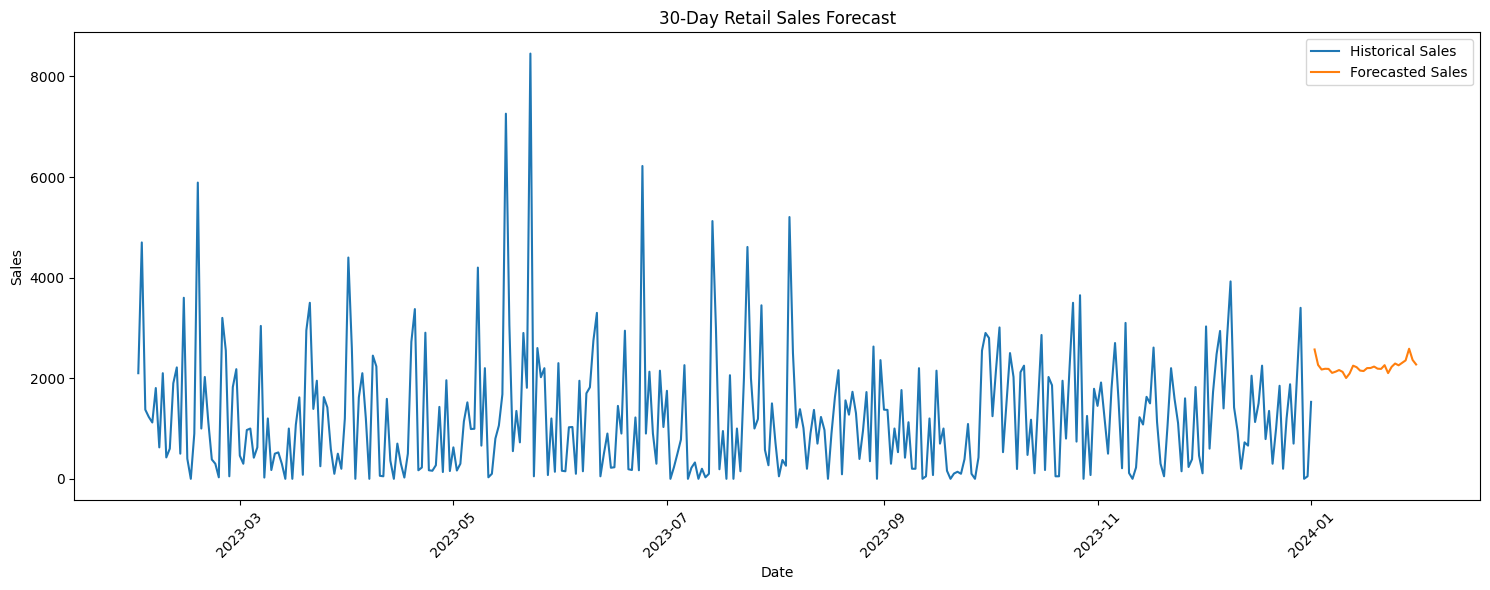

In [67]:
plt.figure(figsize=(15, 6))

plt.plot(
    model_df[date_column],
    model_df[sales_column],
    label="Historical Sales"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Forecasted Sales"],
    label="Forecasted Sales"
)

plt.title("30-Day Retail Sales Forecast")

plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

# 30-Day Sales Forecast Summary

In [68]:
print("30-Day Sales Forecast Summary")
print("--------------------------------")

print(
    "Total Forecasted Sales:",
    round(
        forecast_df["Forecasted Sales"].sum(),
        2
    )
)

print(
    "Average Daily Forecast:",
    round(
        forecast_df["Forecasted Sales"].mean(),
        2
    )
)

print(
    "Maximum Forecast:",
    round(
        forecast_df["Forecasted Sales"].max(),
        2
    )
)

print(
    "Minimum Forecast:",
    round(
        forecast_df["Forecasted Sales"].min(),
        2
    )
)

30-Day Sales Forecast Summary
--------------------------------
Total Forecasted Sales: 66804.86
Average Daily Forecast: 2226.83
Maximum Forecast: 2586.19
Minimum Forecast: 2004.85


In [69]:
forecast_df["Month"] = (
    forecast_df["Date"]
    .dt.to_period("M")
)

monthly_forecast = (
    forecast_df
    .groupby("Month")["Forecasted Sales"]
    .sum()
    .reset_index()
)

monthly_forecast

,Month,Forecasted Sales
0,2024-01,66804.855991


In [70]:
forecast_df.to_csv(
    "retail_sales_30_day_forecast.csv",
    index=False
)

print(
    "Forecast exported as retail_sales_30_day_forecast.csv"
)

Forecast exported as retail_sales_30_day_forecast.csv


# RETAIL SALES KPI SUMMARY

In [72]:
total_sales = df[sales_column].sum()

average_sales = df[sales_column].mean()

total_transactions = len(df)

maximum_sale = df[sales_column].max()

minimum_sale = df[sales_column].min()

print("RETAIL SALES KPI SUMMARY")
print("=========================")

print(
    "Total Sales:",
    round(total_sales, 2)
)

print(
    "Average Transaction:",
    round(average_sales, 2)
)

print(
    "Total Transactions:",
    total_transactions
)

print(
    "Maximum Transaction:",
    round(maximum_sale, 2)
)

print(
    "Minimum Transaction:",
    round(minimum_sale, 2)
)

RETAIL SALES KPI SUMMARY
Total Sales: 456000
Average Transaction: 456.0
Total Transactions: 1000
Maximum Transaction: 2000
Minimum Transaction: 25


# KPI Value

In [74]:
kpi_df = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Average Transaction",
        "Total Transactions",
        "Maximum Transaction",
        "Minimum Transaction",
        "Linear Regression R2",
        "Random Forest R2",
        "Linear Regression Accuracy",
        "Random Forest Accuracy"
    ],

    "Value": [
        total_sales,
        average_sales,
        total_transactions,
        maximum_sale,
        minimum_sale,
        r2_lr,
        r2_rf,
        accuracy_lr,
        accuracy_rf
    ]
})

kpi_df

,KPI,Value
0,Total Sales,456000.000000
1,Average Transaction,456.000000
2,Total Transactions,1000.000000
3,Maximum Transaction,2000.000000
4,Minimum Transaction,25.000000
5,Linear Regression R2,-0.106686
6,Random Forest R2,-0.260611
7,Linear Regression Accuracy,-4125.984692
8,Random Forest Accuracy,-7754.950621


# RETAIL SALES FORECASTING SYSTEM

In [76]:
print("=" * 60)
print("RETAIL SALES FORECASTING SYSTEM")
print("=" * 60)

print("\nDATASET")
print("-" * 60)
print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nLINEAR REGRESSION")
print("-" * 60)
print("MAE:", round(mae_lr, 2))
print("RMSE:", round(rmse_lr, 2))
print("R2 Score:", round(r2_lr, 4))
print("MAPE:", round(mape_lr, 2), "%")
print("Accuracy:", round(accuracy_lr, 2), "%")

print("\nRANDOM FOREST")
print("-" * 60)
print("MAE:", round(mae_rf, 2))
print("RMSE:", round(rmse_rf, 2))
print("R2 Score:", round(r2_rf, 4))
print("MAPE:", round(mape_rf, 2), "%")
print("Accuracy:", round(accuracy_rf, 2), "%")

print("\n" + "=" * 60)
print("PROJECT COMPLETED SUCCESSFULLY")
print("=" * 60)

RETAIL SALES FORECASTING SYSTEM

DATASET
------------------------------------------------------------
Rows: 1000
Columns: 16

LINEAR REGRESSION
------------------------------------------------------------
MAE: 794.44
RMSE: 1028.07
R2 Score: -0.1067
MAPE: 4225.98 %
Accuracy: -4125.98 %

RANDOM FOREST
------------------------------------------------------------
MAE: 919.62
RMSE: 1097.24
R2 Score: -0.2606
MAPE: 7854.95 %
Accuracy: -7754.95 %

PROJECT COMPLETED SUCCESSFULLY
